# Lab 04: Generating CDFs

Most distributions are discovered by being curious about the world. Someone watches a phenomenon unfold, asks what mechanism could generate it, and then recognizes the mathematical pattern. It's good to remember that math is discovered, not invented.

In each of the following parts, there is a description of a simulation. Each of these simulations generates one of the distributions below, along with its name in `scipy.stats`:

| Distribution | SciPy PDF/PMF | SciPy CDF | Parameters |
|---|---|---|---|
| Beta | `beta.pdf(x, a, b)` | `beta.cdf(x, a, b)` | $(a, b)$ |
| Pareto | `pareto.pdf(x, b, scale=xm)` | `pareto.cdf(x, b, scale=xm)` | shape $b$, minimum $x_m$ |
| Uniform | `uniform.pdf(x, loc=a, scale=b-a)` | `uniform.cdf(x, loc=a, scale=b-a)` | lower $a$, upper $b$ |
| Lognormal | `lognorm.pdf(x, s=sigma, scale=np.exp(mu))` | `lognorm.cdf(x, s=sigma, scale=np.exp(mu))` | $\log X \sim N(\mu, \sigma^2)$ |
| Normal | `norm.pdf(x, loc=mu, scale=sigma)` | `norm.cdf(x, loc=mu, scale=sigma)` | $(\mu, \sigma)$ |
| Exponential | `expon.pdf(x, scale=1/lam)` | `expon.cdf(x, scale=1/lam)` | $\lambda$ |

For parts 1-8 below, program and run the described simulation, plot its distribution using the ECDF, and compare with the distributions above.

**Which simulations generate which CDFs?**

**Pick four simulations to complete. You do not have to do all of them.**


In [13]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
import seaborn as sns 
rng = np.random.default_rng(seed=100)

## Q1.

OK, a warm-up, just to get started.

1. Set up a grid of $K$ equally spaced values between 0 and 1, $\{1/K,\ 2/K,\ ...,\ K/K\}$.
2. Draw a point from the grid at random with equal probability.
3. For a very small $K$, repeat the above process `n = 5_000` times, and plot the ECDF of the draws.
4. What distribution does this approach as you increase $K$?


<Axes: ylabel='Proportion'>

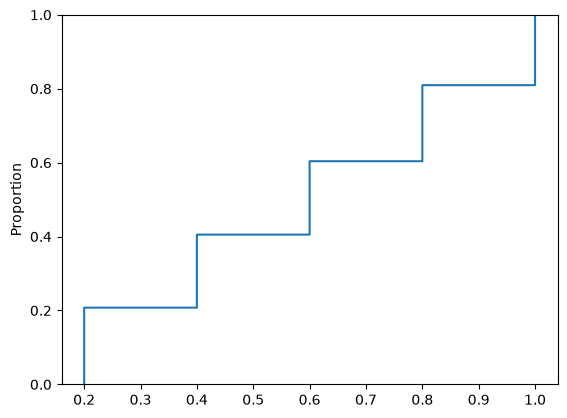

In [14]:
K = 5
n = 5_000

grid = np.arange(1, K+1)/ K
draws = rng.choice(grid, size =n)

sns.ecdfplot(x = draws)

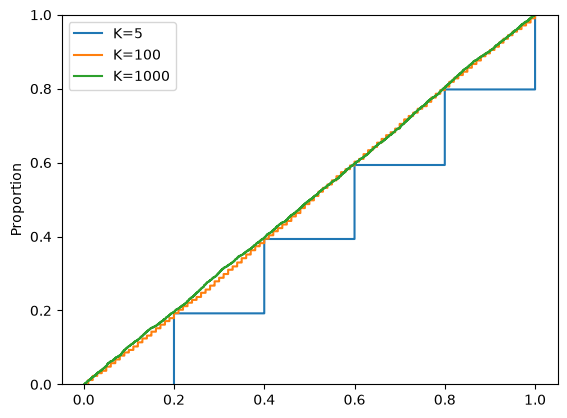

In [15]:
for K in [5, 100, 1000]:
    grid = np.arange(1, K + 1) / K
    draws = rng.choice(grid, size=n)
    sns.ecdfplot(x=draws, label=f"K={K}")

plt.legend()
plt.show()

**Answer:**

As K increases, the distribution approaches a Uniform distribution. Increasing K creates icreases the number of steps to reach 1 and also makes the size smaller so the discrete distribution increasingly resembles a continuous Uniform distribution with increase is K.


## Q2.

We often study sample averages: It's one of the first statistics you calculate for any dataset. What is the distribution of the sample mean?

1. Draw `n = 32` values from Uniform$[-\sqrt{3},\ \sqrt{3}]$; these are your data. The choice of $\pm\sqrt{3}$ ensures each draw has mean 0 and variance 1.
2. For this sample, compute the mean and multiply by `np.sqrt(n)`.
3. Repeat the above process `b = 5_000` times and plot the ECDF.
4. What distribution does this approach as $n$ increases?


In [16]:
n = 32

sample = rng.uniform(-np.sqrt(3), np.sqrt(3), size=n)

In [17]:
result = sample.mean() * np.sqrt(n)

In [18]:
n = 32
B = 5000

result = []

for i in range(B):
    sample = rng.uniform(-np.sqrt(3), np.sqrt(3), size=n)
    R = sample.mean() * np.sqrt(n)
    result.append(R)

<Axes: ylabel='Proportion'>

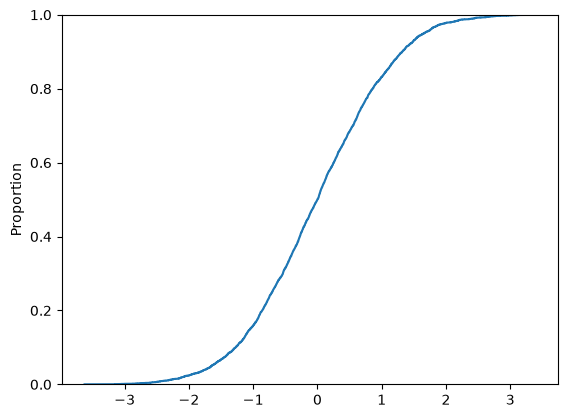

In [19]:
sns.ecdfplot(x=result)

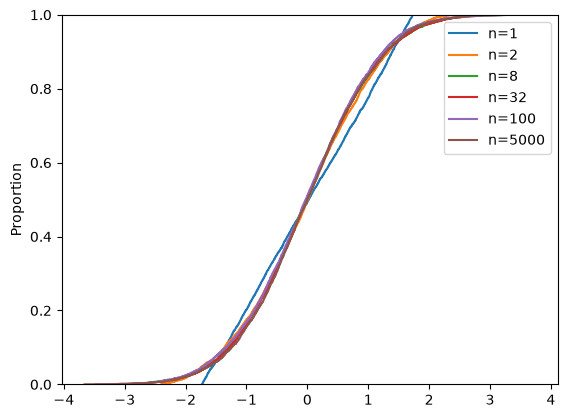

In [20]:
for n in [1, 2, 8, 32, 100, 5000]:

    result = []

    for i in range(B):
        sample = rng.uniform(-np.sqrt(3), np.sqrt(3), size=n)
        R = sample.mean() * np.sqrt(n)
        result.append(R)

    sns.ecdfplot(x=result, label=f"n={n}")
    plt.legend()

**Answer:**

The distribution of the sample mean approaches a Normal distribution as n increases. When n = 1, there is no averaging, so the mean is just the one value that was drawn. Therefore, the distribution looks like the original Uniform distribution, similar to Q1. As n increases, each mean is calculated using more values, so extreme means become less likely and the sample means become closer together. Without multiplying by sqrt(n), the means would eventually become so close together that the graph would look almost like a straight vertical line. Multiplying by sqrt(n) spreads these values out, allowing us to see that the distribution approaches a Normal distribution with an S-shaped CDF. B = 5000 is the number of times the experiment is repeated, while n is the number of values used to calculate each sample mean.

## Q3.

In reliability engineering, we are often concerned with the proportions of failures that occur. For example, the Challenger space shuttle exploded on January 28, 1986, when the primary and secondary o-rings failed. Floods often occur because too many levees or pumps are compromised. In this simulation, we have 40 units that each fail with probability $p$, and we want to study the distribution of the survivors.

1. Flip `n = 40` coins, which each come up heads with probability $p = 1/2$ and tails with complementary probability.
2. From the final count of heads, subtract the expected number of heads, `n * p`.
3. Divide by the standard deviation `sqrt( n * p * (1-p) )`.
4. Repeat the above process `b = 5_000` times and plot the ECDF.
5. What distribution does this approach as $n$ increases?
6. How do the results change as you adjust $p$?


In [21]:
n = 40
p= 1/2

X = rng.binomial(n,p) 

std = (X - n*p)/np.sqrt(n* p * (1-p))
# 1-3. Flip n = 40 coins with p = 1/2, standardize the head count


# 4. Repeat b = 5_000 times, plot the ECDF


# 5-6. Try varying n and p -- how does the ECDF change?


In [22]:
B = 5_000

result =[]

for i in range(B):
    X = rng.binomial(n,p)
    std = (X - n*p)/np.sqrt(n* p * (1-p))
    result.append(std)


<Axes: ylabel='Proportion'>

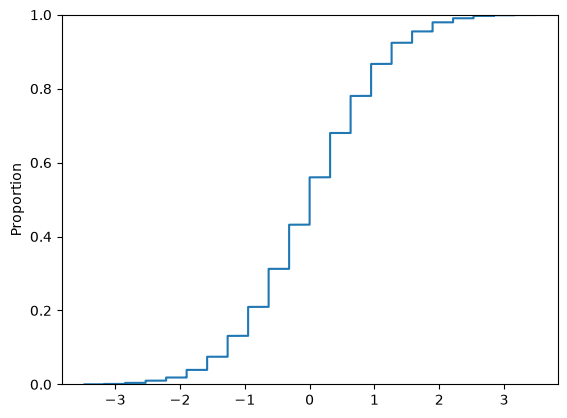

In [23]:
sns.ecdfplot(x=result)

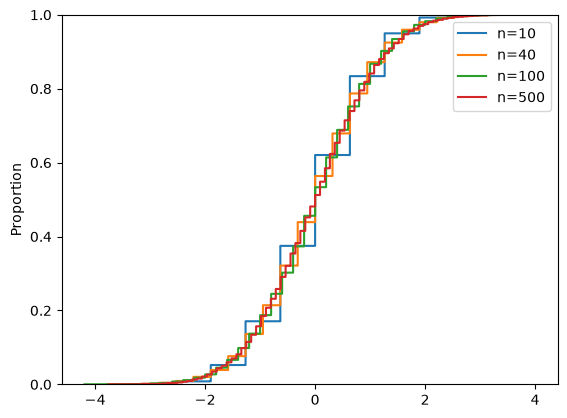

In [24]:
rng = np.random.default_rng(seed=100)

p = 0.5
B = 5_000

for n in [10, 40, 100, 500]:

    result = []

    for i in range(B):
        X = rng.binomial(n, p)
        Z = (X - n*p) / np.sqrt(n*p*(1-p))
        result.append(Z)

    sns.ecdfplot(x=result, label=f"n={n}")

plt.legend()
plt.show()

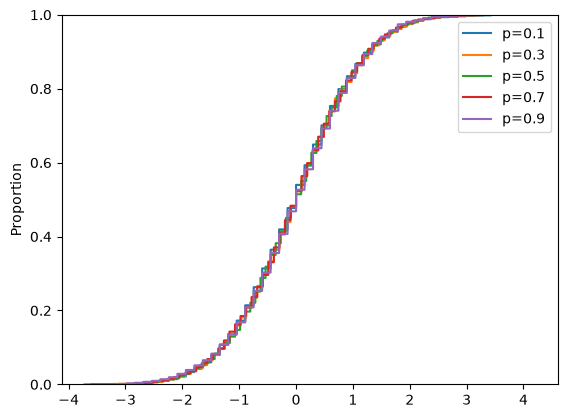

In [25]:
for p in [0.1, 0.3, 0.5, 0.7, 0.9]:

    result = []

    for i in range(B):
        X = rng.binomial(n, p)
        Z = (X - n*p) / np.sqrt(n*p*(1-p))
        result.append(Z)

    sns.ecdfplot(x=result, label=f"p={p}")

plt.legend()
plt.show()

**Answer:**

 The ECDF has a step like appearance because the number of heads from the 40 coin flips is a discrete random variable. Even though the experiment is repeated 5000 times the number of heads can only take integer values from 0 to 40 so after standardizing the counts many of the 5,000 repetitions produce the same possible values. This causes the ECDF to jump at specific points rather than appearing completely smooth. This differs from Question 2, where the original observations were drawn from a continuous Uniform distribution. In Q2, the sample means could take many different continuous values so the 5000 simulated statistics were much less likely to be identical and the resulting ECDF appeared much smoother. When I varied n in 3 the ECDF became smoother as n increased. With n=10, there are relatively few possible head counts, producing large, visible steps, while n=40, 100, and 500 provide increasingly more possible values and therefore smaller steps. The curves also increasingly resemble the CDF of a standard Normal distribution, showing that the standardized Binomial variable approaches normal as n increases. When I kept n=40 and varied p the ECDFs remained centered in approximately the same region because the counts were standardized. However, changing p affects the shape of the underlying Binomial distribution. When p is near 0.5, the distribution is more symmetric, while values closer to 0 or 1 produce more of a skewed result. In my graph, the ECDFs for the different values of p are still very similar and largely overlap after standardization, although small differences can be seen in their steps and shape. Overall, increasing n makes the discrete standardized Binomial distribution look increasingly continuous and Normal like, while changing p affects its symmetry.

## Q4.

A process is running in discrete time. In each time interval of length `dt`, it terminates with probability `r * dt`, where `r * dt < 1`. This is called an arrival, death, or survival process, and is popular for modeling how long patients live after a procedure, whether an employee quits, or the arrival of the next goal in a sportsball match.

1. For each simulation of the process, determine the period in which termination occurs.
2. Convert periods to time by multiplying by `dt`.
3. Repeat the simulation `n = 5_000` times and plot the ECDF, for a value of `dt` close to zero (e.g. `dt = 1e-3`).
4. What distribution does this approach as `dt` goes to zero?
5. How do the results change as you adjust $r$?


<Axes: ylabel='Proportion'>

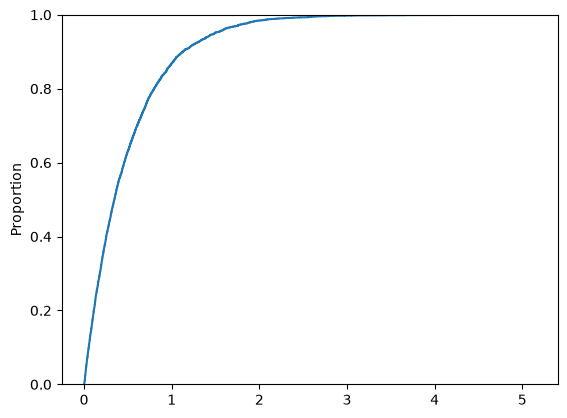

In [26]:
# TODO: Q4 simulation
# 1-3. Simulate the discrete-time termination process, convert to time, plot the ECDF
rng = np.random.default_rng(seed=100)

dt = 1e-3
r = 2
B = 5_000

result = []

for i in range(B):
    period = rng.geometric(r * dt)
    time = period * dt
    result.append(time)

sns.ecdfplot(x=result)


# 4-5. Try varying dt (closer to zero) and r -- how does the ECDF change?


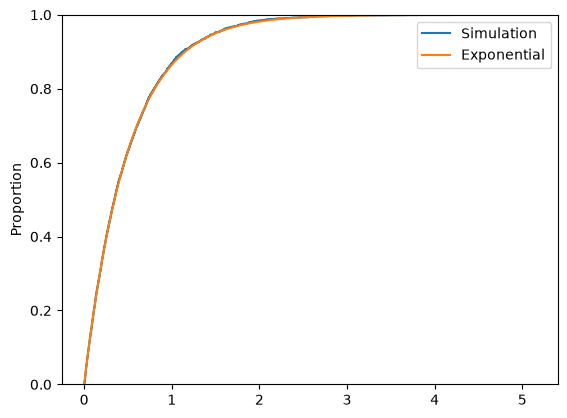

In [27]:
sns.ecdfplot(x=result, label="Simulation")

x = np.linspace(0, max(result), 1000)

plt.plot(
    x,
    stats.expon.cdf(x, scale=1/r),
    label="Exponential"
)

plt.legend()
plt.show()

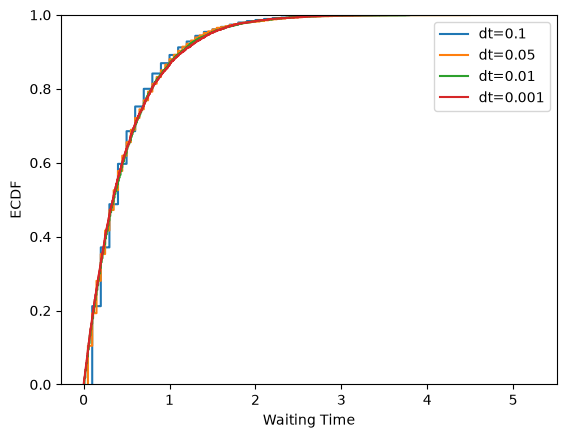

In [33]:

r = 2
B = 5_000

for dt in [0.1, 0.05, 0.01, 0.001]:

    result = []

    for i in range(B):
        period = rng.geometric(r * dt)
        time = period * dt
        result.append(time)

    sns.ecdfplot(x=result, label=f"dt={dt}")

plt.xlabel("Waiting Time")
plt.ylabel("ECDF")
plt.legend()
plt.show()

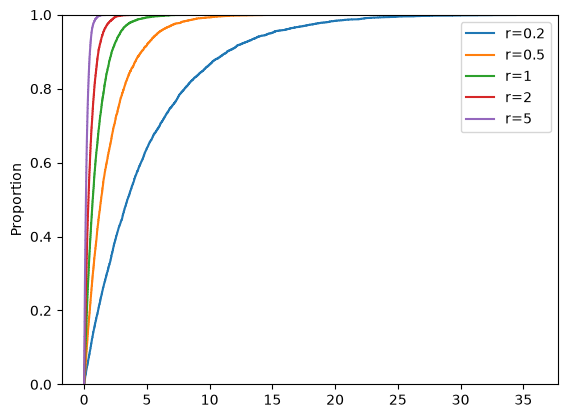

In [28]:
for r in [0.2,0.5, 1, 2, 5]:

    result = []

    for i in range(B):
        period = rng.geometric(r * dt)
        time = period * dt
        result.append(time)

    sns.ecdfplot(x=result, label=f"r={r}")

plt.legend()
plt.show()

**Answer:**

As dt decreases, the ECDF approaches an Exponential distribution. Larger values of dt represent larger time intervals, so the possible waiting times are more spread out and the ECDF appears more step-like or chunky. Smaller values of dt represent much smaller time intervals, so the possible waiting times are closer together and the ECDF becomes smoother. The Exponential shape occurs because the process must continue surviving each time interval to reach the next one. Since the probability of surviving each interval is the same, the probability of continuing to survive gets smaller as more time passes. As dt approaches 0, the discrete waiting-time process approaches a continuous Exponential distribution.

R, The rate at which the process terminates. A larger r means there is a greater chance of termination in each time interval, so the ECDF rises faster and reaches 1 sooner. A smaller r means termination is less likely in each interval, so the process tends to survive longer and the ECDF rises more slowly. Therefore, increasing r results in shorter waiting times, while decreasing r results in longer waiting times.

## Q5.

We're going to draw a sample of values, sort them, and track a particular rank. This is particularly useful for understanding **extreme events**: We might be interested in the behavior of the biggest storm or earthquake each year, but be working with a dataset about storms in general over 25 or 50 years.

1. Draw $K = 20$ values from Uniform$[0,\ 1]$.
2. Sort them by size from smallest to largest.
3. Record the largest value.
4. Repeat `n` times and plot the ECDF.
5. Repeat the previous steps for each rank from 1 to $K$.
6. What distribution(s) does this process generate? How does the distribution depend on the rank?


In [29]:
# TODO: Q5 simulation
# 1-4. Draw K = 20 Uniform[0,1] values, sort, record the largest, repeat n times, plot ECDF


# 5. Repeat for each rank from 1 to K -- how does the ECDF change by rank?


**Answer:**

*(your written answer here)*

## Q6.

Many things in the world grow through a long sequence of small proportional gains and losses: prices bounce around in response to information, tumors grow and shrink, populations expand and contract. When those tiny changes accumulate randomly over time, they produce recognizable patterns.

1. Start at a state of 1.
2. Split a unit of time into $1/\Delta$ small time steps. Start with $\Delta = 1/100$, so $\{0, 1/100, 2/100, ..., 99/100\}$.
3. Each period, the state is multiplied by $u = \exp(\sqrt{\Delta})$ with probability $p = 1/2$ or multiplied by $d = \exp(-\sqrt{\Delta})$ with probability $1-p = 1/2$.
4. Repeat steps 1-3 `B = 1_000` times and record the final position, and plot the ECDF of your sample.
5. What distribution does this approach as $\Delta$ gets close to zero?


In [30]:
# TODO: Q6 simulation
# 1-3. Multiplicative random walk: start at 1, step by u or d each period


# 4. Repeat B = 1_000 times, record final position, plot the ECDF


# 5. Try shrinking Delta -- how does the ECDF change?


**Answer:**

*(your written answer here)*

## Q7.

A surprising regularity appears again and again in human populations: the second-largest city is often roughly half the size of the largest, the third-largest roughly one-third the size, and so on. This relationship is called Zipf's law, and it connects the rank of an observation to its size.

1. Suppose there are `K = 100_000` cities, ranked from largest to smallest. Create the ranks $r = \{1, ..., K\}$.
2. Zipf's law says that the size of the city with rank $r$ is proportional to $x_r = (K/r)^s$. Start with $s = 1$.
3. Randomly sample `n=5_000` ranks, with each rank equally likely, and record the corresponding sizes.
4. Plot the ECDF of the simulated sizes.
5. What distribution does this generate as $K$ becomes large?
6. How does the distribution change as you adjust $s$?


In [31]:
# TODO: Q7 simulation
# 1-3. Build the K = 100_000 ranks, compute Zipf sizes x_r = (K/r)^s, sample n = 5_000 ranks


# 4. Plot the ECDF of the simulated sizes


# 5-6. Try varying K and s -- how does the ECDF change?


**Answer:**

*(your written answer here)*

## Q8.

Imagine a toy model of a collection of particles constantly colliding and exchanging energy, while the total amount of energy in the system remains fixed. No particle keeps its energy forever: repeated random exchanges eventually produce a stable distribution even though every individual particle continues to change.

1. Initialize `n = 1_000` particles with energy $E_i = 1$.
2. Randomly choose two particles $i$ and $j$. Add their energies, $E = E_i + E_j$.
3. Draw a uniformly distributed number between 0 and 1, $u$, and redistribute the energy: $E_i = uE$ and $E_j = (1-u)E$.
4. Repeat this random exchange `b=1_000_000` times.
5. Record the final energies of all particles and plot their ECDF.
6. What distribution does this simulation approach as $n$ becomes large?
7. How does the distribution change if you increase or decrease the initial energy for each particle?


In [32]:
# TODO: Q8 simulation
# 1-4. Initialize n = 1_000 particles with E_i = 1, repeatedly pick two at random and redistribute their combined energy


# 5. Plot the ECDF of the final energies


# 6-7. Try varying n and the initial energy -- how does the ECDF change?


**Answer:**

*(your written answer here)*